In [1]:
import matplotlib.pyplot as plt
import numpy as np

from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix

# Regression Visualization
Predecir valores numericos continuos

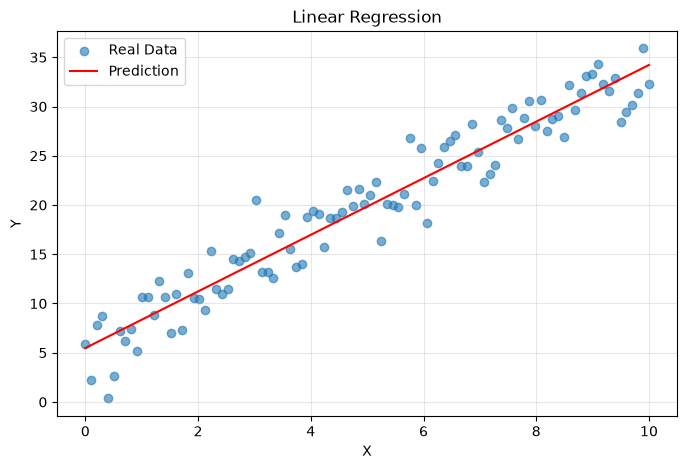

In [ ]:
# Datos simulados
rng = np.random.default_rng(42)

X = np.linspace(0, 10, 100).reshape(-1, 1) # 100 numeros aleatorios entre 0 y 10, y convierte en un arreglo de 100 filas y una columna
y = 3 * X.ravel() + 5 + rng.normal(0, 3, 100) # x.ravel lo convierte a un dimension, hace operación y al final añade ruido

# Entrenamiento del modelo
model = LinearRegression()
model.fit(X, y)

y_pred = model.predict(X)

# Visualización de valores reales y predicciones
fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(X.ravel(), y, label="Real Data", alpha=0.6)
ax.plot(X.ravel(), y_pred, color="red", label="Prediction")

ax.set_title("Linear Regression")
ax.set_xlabel("X")
ax.set_ylabel("Y")

ax.legend()
ax.grid(alpha=0.3)

plt.show()

Los puntos representan observaciones reales, mientras que la línea muestra las predicciones del modelos. Cuanto mas cerca esten los puntos de la línea, menores serán los errores de predicción.

# Residual Plots
Los residuos representan la diferentes entre los valores reales y los valores predichos, nos permite identificar patrones en los errores del modelo.

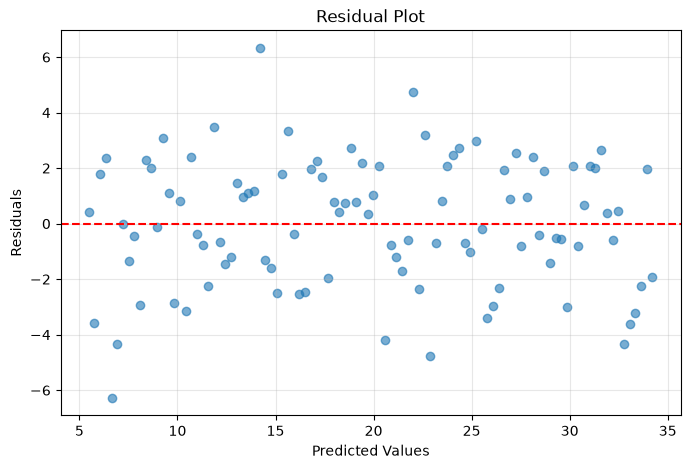

In [3]:
residuals = y - y_pred

fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(y_pred, residuals, alpha=0.6)

ax.axhline(
    y=0,
    color="red",
    linestyle="--"
)

ax.set_title("Residual Plot")
ax.set_xlabel("Predicted Values")
ax.set_ylabel("Residuals")

ax.grid(alpha=0.3)

plt.show()

Cuando los residuos están dispersos alrededor del cero y no presenta patrones evidentes, es una señal favorable.


Si presentan una curva, tendencia o una dispersión creciente, puede existir una relación que el modelo no está capturando correctamente

# Classification - Decision Boundaries
Una decision boundary es la frontera que separa las regiones donde un clasificar predice distintas clases

In [4]:
X, y = make_blobs(
    n_samples=300,
    centers=2,
    cluster_std=2,
    random_state=42
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [5]:
model = LogisticRegression()
model.fit(X_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

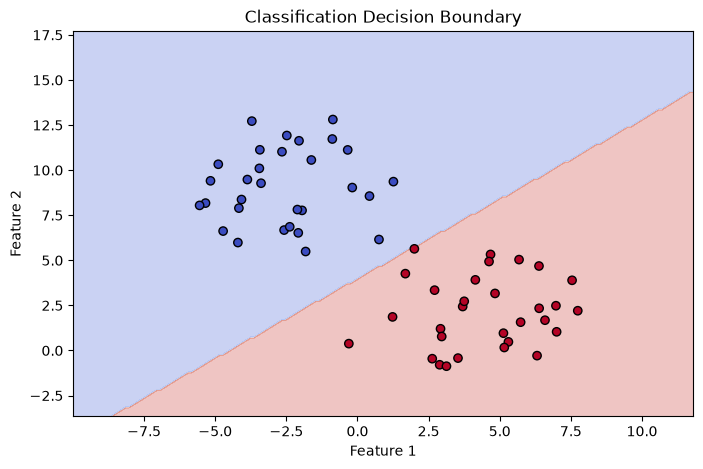

In [ ]:
# Create a grid
x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 200),
    np.linspace(y_min, y_max, 200)
) # genera una cuadricula de coordenadas

# Predict each grid point
grid = np.c_[xx.ravel(), yy.ravel()] # combina las coordenadas en pares
Z = model.predict(grid).reshape(xx.shape)

# Plot
fig, ax = plt.subplots(figsize=(8, 5))

ax.contourf(xx, yy, Z, alpha=0.3, cmap="coolwarm")

ax.scatter(
    X_test[:, 0],
    X_test[:, 1],
    c=y_test,
    cmap="coolwarm",
    edgecolor="black"
)

ax.set_title("Classification Decision Boundary")
ax.set_xlabel("Feature 1")
ax.set_ylabel("Feature 2")

plt.show()

# Confusion Matrix
Permite comparar las clases reales con las clases predichas por un clasificador

In [7]:
# Genera predicciones

y_pred = model.predict(X_test)

cm = confusion_matrix(y_test, y_pred)

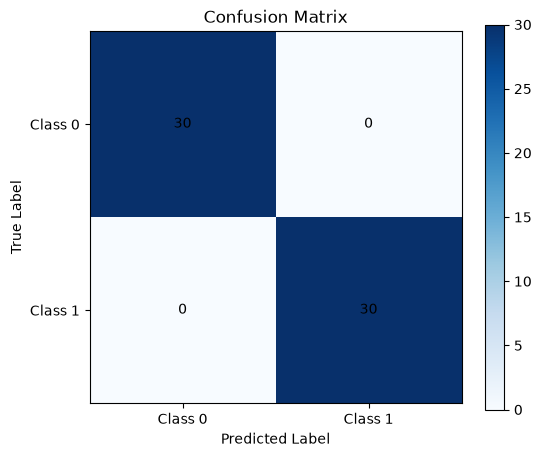

In [8]:
fig, ax = plt.subplots(figsize=(6, 5))

im = ax.imshow(cm, cmap="Blues")

ax.set_xticks([0, 1], labels=["Class 0", "Class 1"])
ax.set_yticks([0, 1], labels=["Class 0", "Class 1"])

ax.set_xlabel("Predicted Label")
ax.set_ylabel("True Label")
ax.set_title("Confusion Matrix")

# Display values
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(
            j, i,
            cm[i, j],
            ha="center",
            va="center"
        )

fig.colorbar(im, ax=ax)

plt.show()

# Clustering Visualization
En clustering, los algoritmos intentan agrupar observaciones similares sin conocer previamente sus categorias (K-Means)

In [ ]:
X, _ = make_blobs(
    n_samples=300,
    centers=3,
    cluster_std=1.2,
    random_state=42
)

model = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

clusters = model.fit_predict(X)
centers = model.cluster_centers_ # proporciona las coordenadas de los centroides

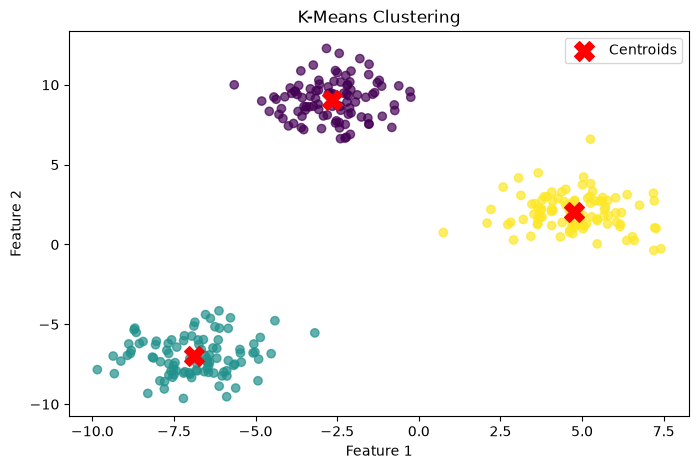

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(
    X[:, 0],
    X[:, 1],
    c=clusters, # asigna un color a cada grupo
    cmap="viridis", # define el mapa de colores
    alpha=0.7
)

ax.scatter(
    centers[:, 0],
    centers[:, 1],
    color="red",
    marker="X",
    s=200,
    label="Centroids"
)

ax.set_title("K-Means Clustering")
ax.set_xlabel("Feature 1")
ax.set_ylabel("Feature 2")
ax.legend()

plt.show()

# Training History Visualization
Es muy habitual visualizar la evolución de la pérdida (loss) y la precisión (accuracy) durante el entrenamiento

In [11]:
epochs = np.arange(1, 11)

train_loss = [
    0.95, 0.82, 0.70, 0.58, 0.49,
    0.42, 0.36, 0.31, 0.27, 0.24
]

val_loss = [
    1.00, 0.87, 0.76, 0.67, 0.61,
    0.59, 0.60, 0.63, 0.67, 0.72
]

train_acc = [
    0.55, 0.62, 0.70, 0.76, 0.81,
    0.85, 0.89, 0.92, 0.95, 0.97
]

val_acc = [
    0.52, 0.60, 0.68, 0.73, 0.78,
    0.80, 0.82, 0.83, 0.82, 0.81
]

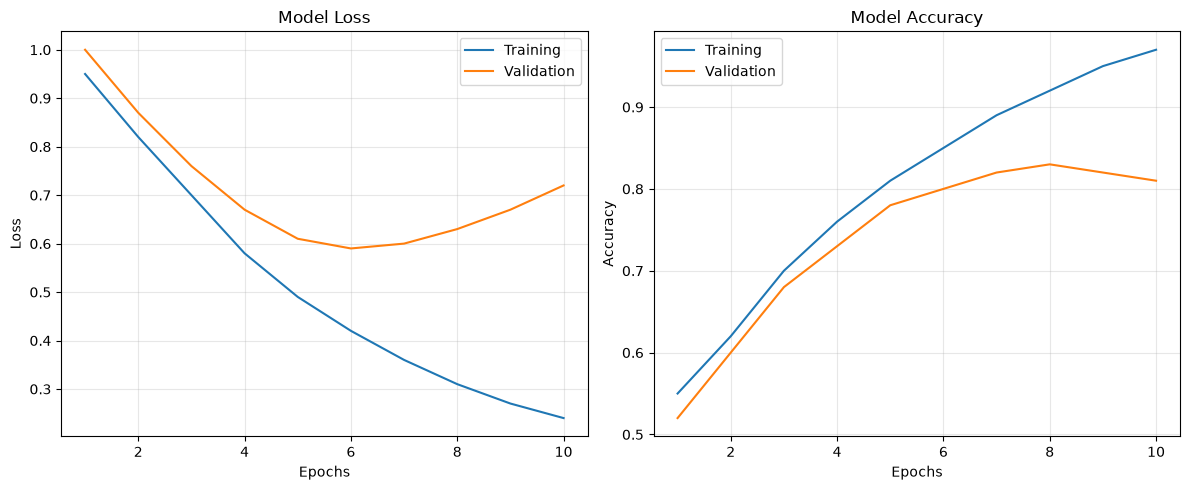

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Loss
axes[0].plot(epochs, train_loss, label="Training")
axes[0].plot(epochs, val_loss, label="Validation")

axes[0].set_title("Model Loss")
axes[0].set_xlabel("Epochs")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Accuracy
axes[1].plot(epochs, train_acc, label="Training")
axes[1].plot(epochs, val_acc, label="Validation")

axes[1].set_title("Model Accuracy")
axes[1].set_xlabel("Epochs")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(alpha=0.3)

fig.tight_layout()
plt.show()

Train y Validation Loss disminuyen | El modelo está aprendiendo.


Train Loss disminuye, Validation Loss aumenta | Posible overfitting.


Ambas pérdidas permanecen elevadas | Posible underfitting.


Las curvas oscilan considerablemente | Posible inestabilidad del entrenamiento.

